In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("Airbnb_data.csv")

In [7]:
'''
rename column

1. ID -> listing_id
2. name -> listing_name
3. number_of_review -> total_review
4. calculated_host_listing_count -> host_listing_count

'''

df.rename(columns={
    'id': 'listing_id',
    'name': 'listing_name',
    'number_of_reviews': 'total_review',
    'calculated_host_listings_count': 'host_listing_count'
}, inplace=True)

In [9]:
df.columns

Index(['listing_id', 'listing_name', 'host_id', 'host_name',
       'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'total_review', 'last_review',
       'reviews_per_month', 'host_listing_count', 'availability_365'],
      dtype='object')

In [13]:
'''
1.Info of data
2.check the statistical summary of data
3.check for duplicates
4.check null values

'''

'\n1.Info of data\n2.check the statistical summary of data\n3.check for duplicates\n4.check null values\n\n'

In [10]:
df.info

<bound method DataFrame.info of        listing_id                                       listing_name  \
0            2539                 Clean & quiet apt home by the park   
1            2595                              Skylit Midtown Castle   
2            3647                THE VILLAGE OF HARLEM....NEW YORK !   
3            3831                    Cozy Entire Floor of Brownstone   
4            5022   Entire Apt: Spacious Studio/Loft by central park   
...           ...                                                ...   
48890    36484665    Charming one bedroom - newly renovated rowhouse   
48891    36485057      Affordable room in Bushwick/East Williamsburg   
48892    36485431            Sunny Studio at Historical Neighborhood   
48893    36485609               43rd St. Time Square-cozy single bed   
48894    36487245  Trendy duplex in the very heart of Hell's Kitchen   

        host_id      host_name neighbourhood_group       neighbourhood  \
0          2787           Joh

In [14]:
df.describe()

,listing_id,host_id,latitude,longitude,price,minimum_nights,total_review,reviews_per_month,host_listing_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.isnull().sum()

listing_id                 0
listing_name              16
host_id                    0
host_name                 21
neighbourhood_group        0
neighbourhood              0
latitude                   0
longitude                  0
room_type                  0
price                      0
minimum_nights             0
total_review               0
last_review            10052
reviews_per_month      10052
host_listing_count         0
availability_365           0
dtype: int64

In [15]:
df['host_name'] = df['host_name'].fillna('Unknown')

In [16]:
df['reviews_per_month']=df['reviews_per_month'].fillna(0)
df=df.drop(['last_review'],axis=1)

In [17]:
df['listing_name'] = df['listing_name'].fillna('Unknown')

In [18]:
df.isnull().sum()

listing_id             0
listing_name           0
host_id                0
host_name              0
neighbourhood_group    0
neighbourhood          0
latitude               0
longitude              0
room_type              0
price                  0
minimum_nights         0
total_review           0
reviews_per_month      0
host_listing_count     0
availability_365       0
dtype: int64

In [19]:
#1.How many unique neighbourhoood we are having in new york city ?
a=df.neighbourhood.nunique()
print(a)

221


In [20]:
#2.How many unique neighbourhoood_group we are having in new york city ?
b=df.neighbourhood_group.nunique()
print(b)

5


In [21]:
#3.how many host we are having?
c=df.host_id.nunique()
print(c)

37457


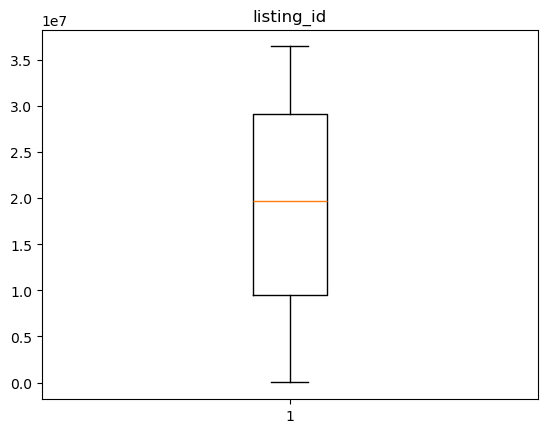

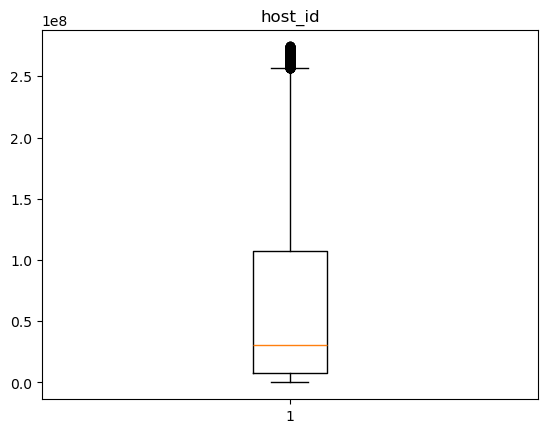

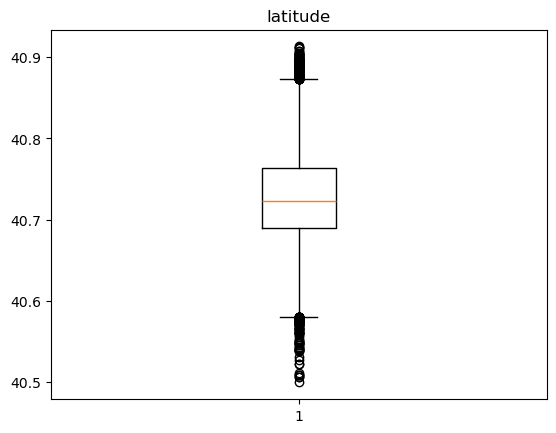

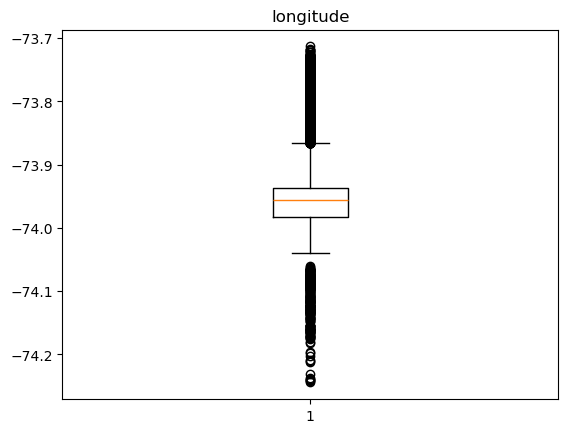

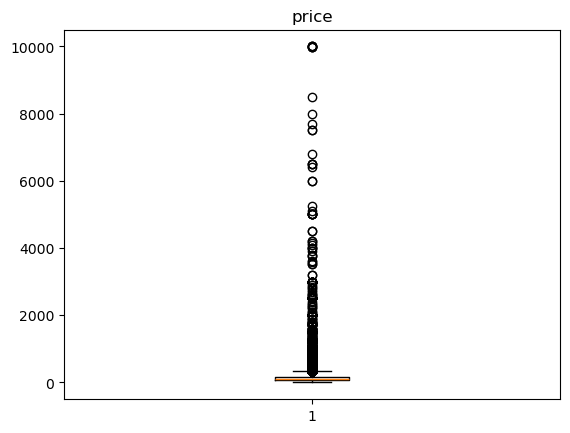

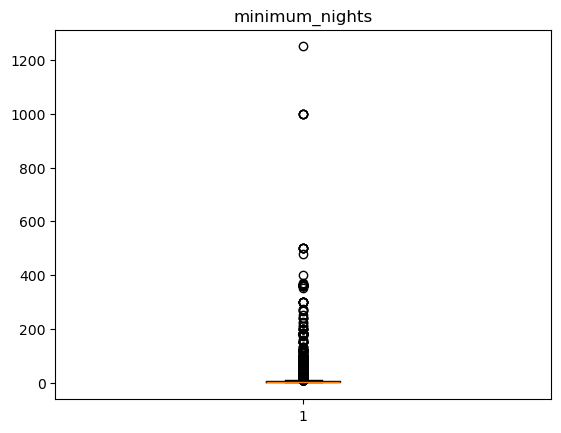

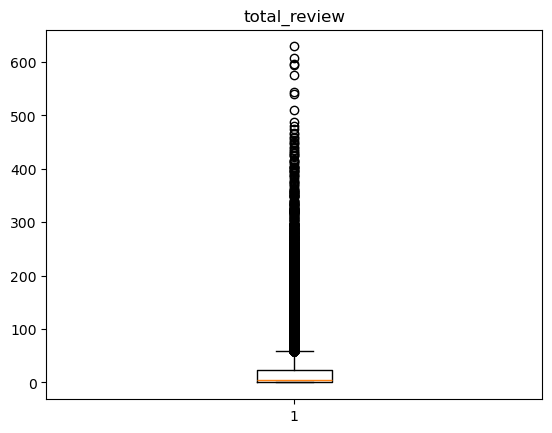

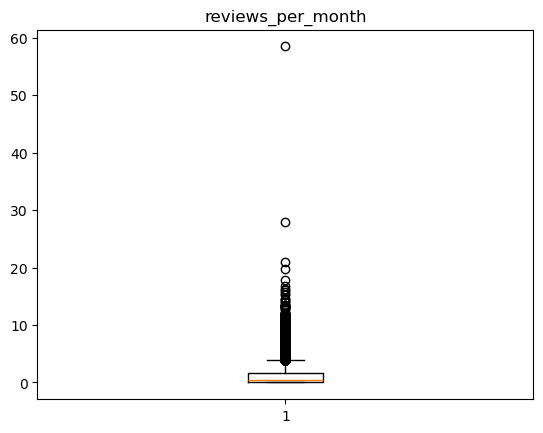

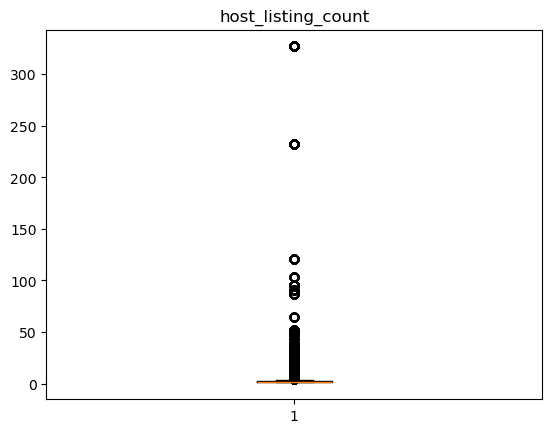

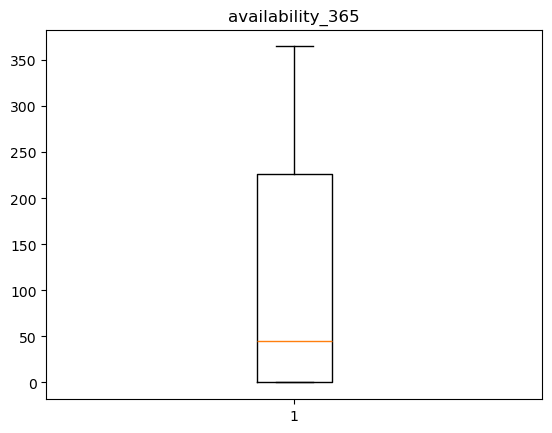

In [22]:
#4.for all numeric value columns show the boxplot for outliers detection?
for i in df.columns:
  if(df[i].dtype != 'object'):
    plt.boxplot(df[i])
    plt.title(i)
    plt.show()

In [23]:
#using iqr method handle outlier --> and create a fuction for handling outlier ?
def handle_outliers(col):
  # Calculate Q1 and Q3
  Q1 = np.percentile(col, 25)
  Q3 = np.percentile(col, 75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  return lower,upper

In [24]:
lower,upper=handle_outliers(df['price'])

In [25]:
lower

np.float64(-90.0)

In [26]:
upper

np.float64(334.0)

In [27]:
df=df[(df['price']>lower) & (df['price']<upper)]

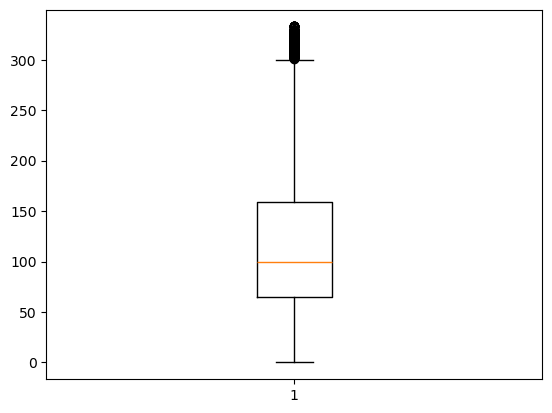

In [28]:
plt.boxplot(df['price'])
plt.show()

Inferential Stats

In [29]:
#Do Airbnb prices diifer siginificantly between manhattan and brooklyn?(using t-test)? s=0.05
from scipy import stats

manhattan=df[df['neighbourhood_group']=='Manhattan']['price']
brooklyn=df[df['neighbourhood_group']=='Brooklyn']['price']

t_stat,p_value=stats.ttest_ind(manhattan,brooklyn,equal_var=False)

print(t_stat)
print(p_value)

60.23315099124513
0.0
